In [1]:
import numpy as np
from lib.dvr1d import *
from lib.utils import *
from lib.vqe import DVR_VQE
from lib.pot_gen import get_pot_cr2
from qiskit.circuit.library import TwoLocal

import matplotlib.pyplot as plt

log_file = 'results/log.txt'
%load_ext autoreload

In [8]:
mol_params = cr2_params
spin = 13
mol_params['name'] += f'_{spin}'

# 16 points
params16 = [5.2, 9]
dvr_options = {
    'type': '1d',
    'box_lims': (params16[0], params16[1]),
    'dx': (params16[1] - params16[0]) / 16,
    'count': 16
}
vqe_options = {
    # 'optimizers': ['L_BFGS_B.8000'],
    'optimizers': ['COBYLA.1000'],
    # 'repeats': 1, 
    'repeats': 2, 
    'beta': [10000 for i in range(5)],
    'seed': 42
}

ansatz_options = {
    'type': 'twolocal',
    'entanglement': 'opt',
    'gates': [3, 1, 9],
    'reps': 2,
}

In [9]:
%autoreload
pot, lims = get_pot_cr2(spin)
dvr_vqe = DVR_VQE(mol_params, pot, log_dir='results/excited_states/', noise_model='sherbrooke')
opt_params = dvr_vqe.get_dvr_vqe(dvr_options, ansatz_options, vqe_options, excited_states=True)

     ┌─────────────┐ ░            ░ ┌─────────────┐ ░       ░                
q_0: ┤ Ry($x_{0}$) ├─░───■────────░─┤ Ry($x_{4}$) ├─░───────░────────────────
     ├─────────────┤ ░   │        ░ ├─────────────┤ ░       ░ ┌─────────────┐
q_1: ┤ Ry($x_{1}$) ├─░───┼────■───░─┤ Ry($x_{5}$) ├─░───■───░─┤ Ry($x_{7}$) ├
     ├─────────────┤ ░ ┌─┴─┐┌─┴─┐ ░ ├─────────────┤ ░ ┌─┴─┐ ░ ├─────────────┤
q_2: ┤ Ry($x_{2}$) ├─░─┤ X ├┤ X ├─░─┤ Ry($x_{6}$) ├─░─┤ X ├─░─┤ Ry($x_{8}$) ├
     ├─────────────┤ ░ └───┘└───┘ ░ └─────────────┘ ░ └───┘ ░ └─────────────┘
q_3: ┤ Ry($x_{3}$) ├─░────────────░─────────────────░───────░────────────────
     └─────────────┘ ░            ░                 ░       ░                
-----------------------------------------
Optimizer: COBYLA        
Options(default_precision=0.0, backend_options={'noise_model': <NoiseModel on ['x', 'sx', 'reset', 'ecr', 'id', 'measure']>, 'basis_gates': ['ecr', 'id', 'rz', 'sx', 'x'], 'coupling_map': [[1, 0], [1, 2], [3, 2], [4, 3], [4, 15], 

In [ ]:
print(np.array(opt_params).shape)

(6, 9)


In [ ]:
ansatz = dvr_vqe.get_ansatz(ansatz_options, 4)
print(ansatz)

     ┌─────────────┐ ░            ░ ┌─────────────┐ ░       ░                
q_0: ┤ Ry($x_{0}$) ├─░───■────────░─┤ Ry($x_{4}$) ├─░───────░────────────────
     ├─────────────┤ ░   │        ░ ├─────────────┤ ░       ░ ┌─────────────┐
q_1: ┤ Ry($x_{1}$) ├─░───┼────■───░─┤ Ry($x_{5}$) ├─░───■───░─┤ Ry($x_{7}$) ├
     ├─────────────┤ ░ ┌─┴─┐┌─┴─┐ ░ ├─────────────┤ ░ ┌─┴─┐ ░ ├─────────────┤
q_2: ┤ Ry($x_{2}$) ├─░─┤ X ├┤ X ├─░─┤ Ry($x_{6}$) ├─░─┤ X ├─░─┤ Ry($x_{8}$) ├
     ├─────────────┤ ░ └───┘└───┘ ░ └─────────────┘ ░ └───┘ ░ └─────────────┘
q_3: ┤ Ry($x_{3}$) ├─░────────────░─────────────────░───────░────────────────
     └─────────────┘ ░            ░                 ░       ░                


In [65]:
gs_circ = ansatz.assign_parameters(opt_params[0], inplace=False)
es1_circ = ansatz.assign_parameters(opt_params[1], inplace=False)
es2_circ = ansatz.assign_parameters(opt_params[2], inplace=False)
es3_circ = ansatz.assign_parameters(opt_params[3], inplace=False)

print(gs_circ)

     ┌─────────────┐ ░            ░ ┌─────────────┐ ░       ░               
q_0: ┤ Ry(-4.7072) ├─░───■────────░─┤ Ry(-3.2015) ├─░───────░───────────────
     ├─────────────┤ ░   │        ░ └┬────────────┤ ░       ░ ┌────────────┐
q_1: ┤ Ry(-2.8131) ├─░───┼────■───░──┤ Ry(1.9425) ├─░───■───░─┤ Ry(-4.195) ├
     └┬────────────┤ ░ ┌─┴─┐┌─┴─┐ ░  ├────────────┤ ░ ┌─┴─┐ ░ ├────────────┤
q_2: ─┤ Ry(5.2985) ├─░─┤ X ├┤ X ├─░──┤ Ry(2.2519) ├─░─┤ X ├─░─┤ Ry(1.3136) ├
     ┌┴────────────┤ ░ └───┘└───┘ ░  └────────────┘ ░ └───┘ ░ └────────────┘
q_3: ┤ Ry(-6.2832) ├─░────────────░─────────────────░───────░───────────────
     └─────────────┘ ░            ░                 ░       ░               


In [66]:
from qiskit.quantum_info import Statevector

gs_sv = Statevector.from_instruction(gs_circ)
es1_sv = Statevector.from_instruction(es1_circ)
es2_sv = Statevector.from_instruction(es2_circ)
es3_sv = Statevector.from_instruction(es3_circ)

[-548.67554318 -497.15325215 -449.26088962 -404.67410888 -362.99006359
 -325.72205626 -294.32712389 -263.10020988 -230.11943577 -196.2987776
 -157.68112791 -131.03499787 -105.54237729  -41.17526055   58.14172189
  249.96266379]
(1.0008154489328103+0j)


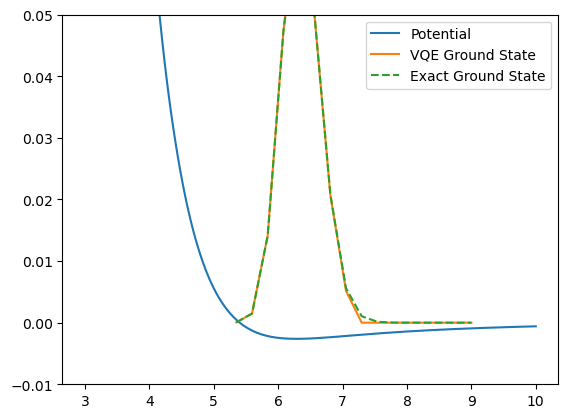

In [74]:
from lib.dvr1d import get_dvr_r, dvr_0inf

dvr_options_exact = {
    'type': '1d',
    'box_lims': (4, 10),
    'dx': (10 - 4) / 64,
    'count': 64
}
h_dvr = dvr_vqe.get_h_dvr(dvr_options, J=0) * hartree
e_vals, e_vecs = np.linalg.eigh(h_dvr)
print(e_vals)

xs = np.linspace(3, 10, 200)
Vs = pot(xs)
plt.plot(xs, Vs, label='Potential')
scale = np.max(gs_sv) / np.max(e_vecs[:,0])
print(scale)
plt.plot(get_dvr_r(dvr_options), gs_sv / scale / 10, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options), e_vecs[:,0] / 10, label='Exact Ground State', ls='--')
plt.ylim(-0.01, 0.05)
plt.legend()



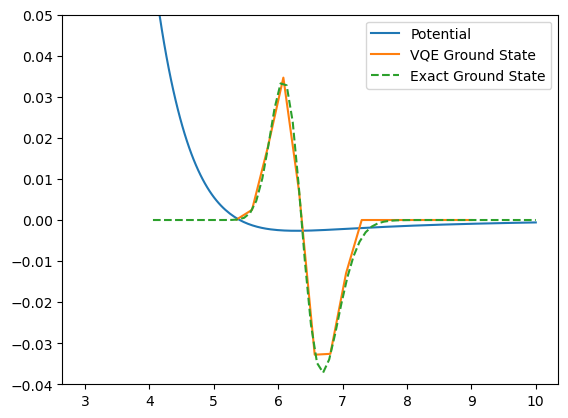

In [62]:
plt.plot(xs, Vs, label='Potential')
plt.plot(get_dvr_r(dvr_options), es1_sv / scale / 10, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options_exact), -e_vecs[:,1] / 10, label='Exact Ground State', ls='--')
plt.ylim(-0.04, 0.05)
plt.legend()

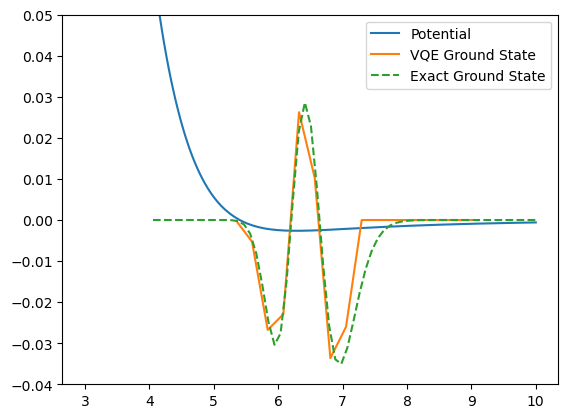

In [64]:
plt.plot(xs, Vs, label='Potential')
plt.plot(get_dvr_r(dvr_options), es2_sv / scale / 10, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options_exact), e_vecs[:,2] / 10, label='Exact Ground State', ls='--')
plt.ylim(-0.04, 0.05)
plt.legend()

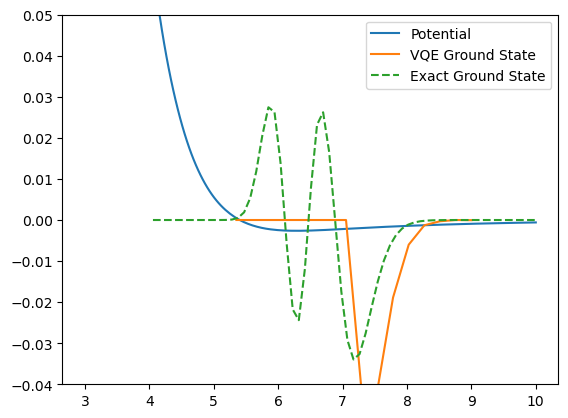

In [67]:
plt.plot(xs, Vs, label='Potential')
plt.plot(get_dvr_r(dvr_options), es3_sv / scale / 10, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options_exact), e_vecs[:,3] / 10, label='Exact Ground State', ls='--')
plt.ylim(-0.04, 0.05)
plt.legend()